# Runtime overhead of MCP tool execution

This experiment measures the execution time of authorized MCP operations in three versions of the same Django application: **Baseline**, **Manual-enforcement**, and **System-enforcement**. The comparison examines the cost of adding access control and the additional cost of enforcing application policies through a reusable System.

Two execution modes are evaluated. **Cold-start** includes a new MCP process and session for every invocation, while **Persistent-session** reuses an initialized session. We first examine each experiment independently, then compare the effects of session reuse and workload size.

The timing results are reported for individual tool operations rather than as a single application-wide average. This keeps the differences between lightweight operations and large file reads visible.

## 1. Experimental design

The evaluation uses the same user, seeded resources, and authorized requests across all three implementations. Each scenario is executed 30 times per run, following two warmup calls. Six runs are performed for each execution mode, covering the six possible implementation orders.

| Setting | Value |
|---|---|
| Implementations | Baseline, Manual-enforcement, System-enforcement |
| Modes | Cold-start, Persistent-session |
| Runs | 6 per mode, with varied implementation order |
| Measurements | 30 timed calls per scenario and implementation, per run |
| Warmup | 2 calls before timed measurements |
| Benchmark coverage | 36 reports, 324 scenario-level benchmarks, 9,720 timed calls |
| Excluded from timing | LLM inference, tool preparation, human confirmation, and post-call verification |

Repeated runs allow us to examine variability between measurements taken under different execution orders. The two modes separate full process-level invocations from repeated calls through an existing MCP session.

The version order changes between runs, so the same implementation is not always tested first. The run-level results also let us check whether the differences hold across repetitions, rather than depending on a single set of measurements.

### 1.1. Benchmark scenarios

The nine scenarios cover filesystem operations, database queries, and file reads with increasing input size.

| Group | Scenario | Tool | Workload |
|---|---|---|---|
| Filesystem | LIST | `list_files` | List files under the user's directory |
| Filesystem | SEARCH | `search_files` | Search for `notes` |
| File reads | READ 1 KiB | `read_file` | Small text document |
| File reads | READ 1 MiB | `read_file` | Medium document |
| File reads | READ 10 MiB | `read_file` | Large CSV file |
| Database | SCHEMA | `get_database_schema` | Retrieve database schema |
| Database | SELECT | `execute_sql` | Read file metadata |
| Database | UPDATE | `execute_sql` | Update a user field |
| Filesystem | DELETE | `delete_file` | Delete a file |

Only successful, authorized operations are included. These benchmarks measure execution latency rather than security-test success rates.

### 1.2. Measurements

Each run is summarized from its 30 timed calls. Statistics are then compared across six runs without treating the 180 calls as independent experimental runs.

| Measurement | Meaning | Role in the analysis |
|---|---|---|
| Mean | Average latency | Overall execution time, including slower calls |
| Median (p50) | Middle latency | Primary typical-latency measure |
| p90 | 90th-percentile latency | Slower requests |
| p95 | 95th-percentile latency | Additional tail-latency check |
| p99 | 99th-percentile latency | Supplementary, less stable with 30 calls |
| SD | Standard deviation | Within-run variation |
| IQR | Middle 50% of timings | Variation less affected by extremes |
| Min / max | Smallest and largest observed latency | Observed range |
| Between-run SD | SD of six run medians | Consistency across runs |
| Overhead (ms) | Difference between implementations | Additional execution time |
| Overhead (%) | Relative difference | Proportional cost |
| 95% CI | Uncertainty in mean overhead across runs | Precision of the estimated difference |
| Input / response bytes | Workload and output sizes | Comparability of operations |

For the six-run summary, mean latency is averaged across run means, while median and percentile results summarize the corresponding statistics from the six runs. Overhead is calculated separately for each run, then summarized across runs.

### 1.3. Setup

In [36]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import t

VERSIONS = ["v1", "v2", "v3"]
LABELS = {"v1": "Baseline", "v2": "Manual-enforcement", "v3": "System-enforcement"}
COLORS = {"v1": "#64748b", "v2": "#15877f", "v3": "#c47f36"}
SCENARIOS = ["list", "search", "read_small", "read_medium", "read_large", "schema", "select", "update", "delete"]
NAMES = {"list": "LIST", "search": "SEARCH", "read_small": "READ 1 KiB", "read_medium": "READ 1 MiB", "read_large": "READ 10 MiB", "schema": "SCHEMA", "select": "SELECT", "update": "UPDATE", "delete": "DELETE"}
SHORT_OPS = ["list", "search", "read_small", "schema", "select", "update", "delete"]
READS = ["read_small", "read_medium", "read_large"]
PAIRS = [("v2", "v1", "Manual vs Baseline"), ("v3", "v1", "System vs Baseline"), ("v3", "v2", "System vs Manual")]
PAIR_COLORS = [COLORS["v2"], COLORS["v3"], "#7764a6"]

In [37]:
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "results/runtime_overhead").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Could not find results/runtime_overhead")
RESULTS = ROOT / "results/runtime_overhead"
OUTPUT = RESULTS / "analysis"
FIGURES = OUTPUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 115})

### 1.4. Load and verify the benchmark results

The raw JSON reports retain individual call times, implementation metadata, and input and response sizes. Timings are converted from seconds to milliseconds before analysis.

The original call times remain available for distribution plots and percentile calculations. We also retain response sizes, since a tool returning more data may take longer even without additional authorization work.

In [38]:
timings, reports, saved_medians = [], [], []
for mode in ["cold_start", "persistent_session"]:
    for path in sorted((RESULTS / mode).glob("run_*/overhead_v*.json")):
        run, version = int(path.parent.name.split("_")[1]), path.stem.split("_")[-1]
        report = json.loads(path.read_text())
        reports.append({"mode": mode, "run": run, "version": version, "commit": report.get("commit_info", {}).get("id"), "branch": report.get("commit_info", {}).get("branch"), "machine": report.get("machine_info", {}).get("node")})
        for item in report["benchmarks"]:
            info, stats = item["extra_info"], item["stats"]
            scenario = info["scenario"]
            saved_medians.append({"mode": mode, "run": run, "version": version, "scenario": scenario, "reported": stats["median"] * 1000})
            for i, seconds in enumerate(stats["data"], 1):
                timings.append({"mode": mode, "run": run, "version": version, "scenario": scenario, "call": i, "ms": seconds * 1000, "input_bytes": info.get("input_bytes"), "response_bytes": info.get("response_bytes")})

samples = pd.DataFrame(timings)
report_info = pd.DataFrame(reports)
recorded = pd.DataFrame(saved_medians)
print(f"{len(report_info)} reports | {len(samples):,} timed calls")

36 reports | 9,720 timed calls


In [39]:
keys = ["mode", "run", "version", "scenario"]
expected = pd.MultiIndex.from_product([["cold_start", "persistent_session"], range(1, 7), VERSIONS, SCENARIOS], names=keys)
counts = samples.groupby(keys).size()
assert len(report_info) == 36 and not report_info.duplicated(["mode", "run", "version"]).any()
assert counts.index.equals(expected.sort_values()) and counts.eq(30).all()
assert np.isfinite(samples["ms"]).all() and samples["ms"].gt(0).all()
assert report_info.groupby(["mode", "version"])[["commit", "branch", "machine"]].nunique(dropna=False).le(1).all().all()
print("All 36 reports and 324 benchmark groups verified")

All 36 reports and 324 benchmark groups verified


### 1.5. Calculate latency statistics

In [40]:
run_stats = samples.groupby(keys, as_index=False).agg(
    n=("ms", "size"), mean=("ms", "mean"), median=("ms", "median"),
    p90=("ms", lambda x: x.quantile(.90)), p95=("ms", lambda x: x.quantile(.95)), p99=("ms", lambda x: x.quantile(.99)),
    sd=("ms", "std"), iqr=("ms", lambda x: x.quantile(.75) - x.quantile(.25)),
    minimum=("ms", "min"), maximum=("ms", "max"),
    input_bytes=("input_bytes", "first"), response_bytes=("response_bytes", "first"))
check = run_stats.merge(recorded, on=keys, validate="one_to_one")
assert np.allclose(check["median"], check["reported"], atol=1e-6)
print(f"{len(run_stats)} per-run summaries")

324 per-run summaries


In [41]:
summary = run_stats.groupby(["mode", "scenario", "version"], as_index=False).agg(
    runs=("run", "nunique"), n=("n", "sum"), mean=("mean", "mean"), median=("median", "median"),
    p90=("p90", "median"), p95=("p95", "median"), p99=("p99", "median"),
    sd=("sd", "median"), iqr=("iqr", "median"), run_sd=("median", "std"),
    run_min=("median", "min"), run_max=("median", "max"), minimum=("minimum", "min"), maximum=("maximum", "max"),
    input_bytes=("input_bytes", "median"), response_bytes=("response_bytes", "median"))
assert summary["runs"].eq(6).all()
print(f"{len(summary)} six-run summaries")

54 six-run summaries


In [42]:
wide = run_stats.pivot(index=["mode", "run", "scenario"], columns="version", values="median").reset_index()
differences = []
for version, reference, name in PAIRS:
    rows = wide[["mode", "run", "scenario"]].copy()
    rows["comparison"] = name
    rows["delta_ms"] = wide[version] - wide[reference]
    rows["delta_pct"] = 100 * (wide[version] / wide[reference] - 1)
    differences.append(rows)
differences = pd.concat(differences, ignore_index=True)

In [43]:
overhead = differences.groupby(["mode", "scenario", "comparison"], as_index=False).agg(
    mean_ms=("delta_ms", "mean"), median_ms=("delta_ms", "median"),
    mean_pct=("delta_pct", "mean"), median_pct=("delta_pct", "median"),
    sd=("delta_ms", "std"), n=("run", "size"))
overhead["ci_margin"] = t.ppf(.975, overhead["n"] - 1) * overhead["sd"] / np.sqrt(overhead["n"])
overhead["ci_low"] = overhead["mean_ms"] - overhead["ci_margin"]
overhead["ci_high"] = overhead["mean_ms"] + overhead["ci_margin"]

## 2. Cold-start experiment

In the Cold-start benchmark, each timed invocation launches an MCP process, establishes a session, executes the requested tool, and closes the session. Consequently, the measured latency includes initialization and communication, not only authorization checks.

This mode reflects the cost of an invocation when the application does not keep its MCP session open. It is useful as an initial measurement, although differences between implementations include more than the policy decision itself.

### 2.1. Run 1 results

The first run is examined before combining repeated runs. The table reports the complete statistics from the 30 timed calls for each operation and implementation. All latency values are in milliseconds.

In [44]:
data = run_stats.query("mode == 'cold_start' and run == 1").copy()
data["Operation"] = data["scenario"].map(NAMES)
data["Implementation"] = data["version"].map(LABELS)
columns = {"n": "Calls", "mean": "Mean", "median": "Median", "p90": "p90", "p95": "p95", "p99": "p99", "sd": "SD", "iqr": "IQR", "minimum": "Min", "maximum": "Max"}
display(data.set_index(["Operation", "Implementation"])[list(columns)].rename(columns=columns).round(2))

,,Calls,Mean,Median,p90,p95,p99,SD,IQR,Min,Max
Operation,Implementation,,,,,,,,,,
DELETE,Baseline,30,779.05,775.86,790.76,796.26,806.46,10.18,13.06,766.07,809.57
LIST,Baseline,30,775.44,766.81,806.94,822.42,841.60,23.59,22.30,746.62,846.89
READ 10 MiB,Baseline,30,1790.16,1733.27,1968.04,2030.62,2100.08,113.84,36.03,1716.93,2116.64
READ 1 MiB,Baseline,30,777.25,768.12,801.39,820.13,864.55,25.05,15.97,757.92,877.15
READ 1 KiB,Baseline,30,762.03,756.28,788.98,805.71,812.62,18.42,11.31,744.86,814.66
SCHEMA,Baseline,30,760.40,754.68,780.46,788.14,812.61,15.91,7.84,746.79,821.40
SEARCH,Baseline,30,772.47,761.52,797.53,809.73,892.89,34.36,26.12,744.04,926.58
SELECT,Baseline,30,752.42,751.68,758.91,761.61,766.83,5.23,5.09,743.85,768.81
UPDATE,Baseline,30,754.86,754.65,760.32,761.47,761.86,4.32,5.89,745.53,762.02


#### Latency by operation

Median and p90 latency are compared for seven filesystem and database operations. The 1 MiB and 10 MiB reads are examined separately because of their larger execution times.
The solid bars represent median execution time, and the lighter section extends to p90. Showing both in one chart lets us compare typical calls without hiding slower executions.

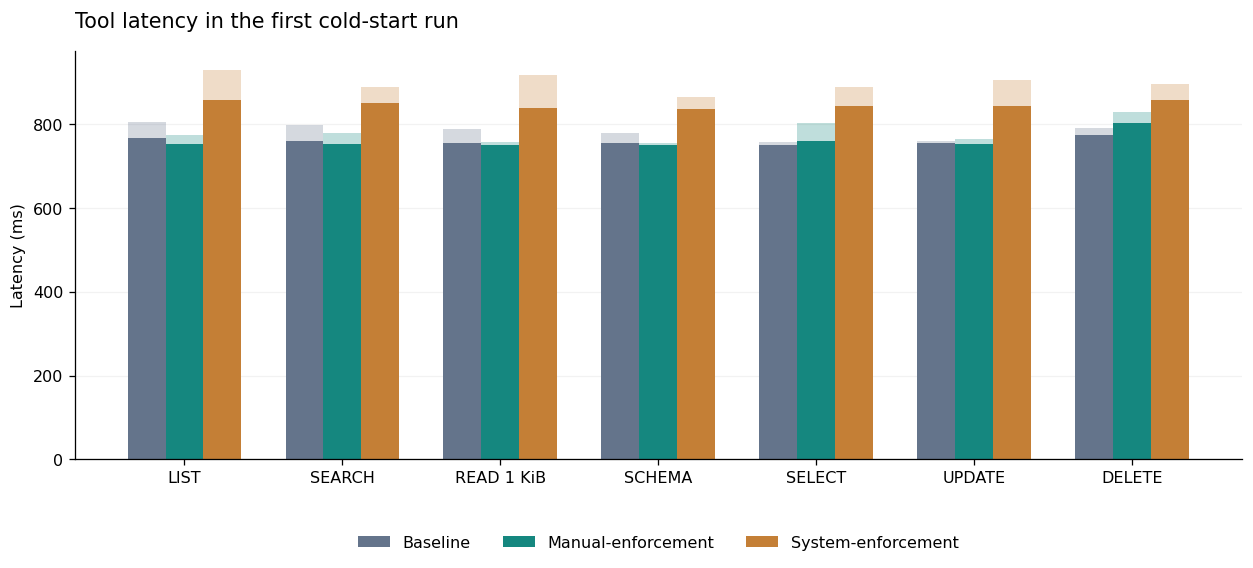

In [45]:
data = run_stats.query("mode == 'cold_start' and run == 1")
operations = SHORT_OPS
fig, ax = plt.subplots(figsize=(11, 5.1))
x, width = np.arange(len(operations)), .24
for i, version in enumerate(VERSIONS):
    rows = data[data["version"] == version].set_index("scenario").loc[operations]
    pos = x + (i - 1) * width
    ax.bar(pos, rows["median"], width, color=COLORS[version], label=LABELS[version])
    ax.bar(pos, rows["p90"] - rows["median"], width, bottom=rows["median"], color=COLORS[version], alpha=.27)
ax.set_xticks(x, [NAMES[s] for s in operations])
ax.set_ylabel("Latency (ms)")
ax.set_title("Tool latency in the first cold-start run", loc="left", fontsize=13, pad=15)
ax.grid(axis="y", alpha=.16)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(.5, -.15))
fig.tight_layout()
fig.savefig(FIGURES / "cold_start_first_run_tool_latency.png", dpi=300, bbox_inches="tight")
plt.show()

#### Distribution of file-read latency

The distribution for READ 1 KiB retains the individual measurements rather than reducing them to a single summary. A curve further to the left indicates faster calls; a steeper curve indicates less variation.

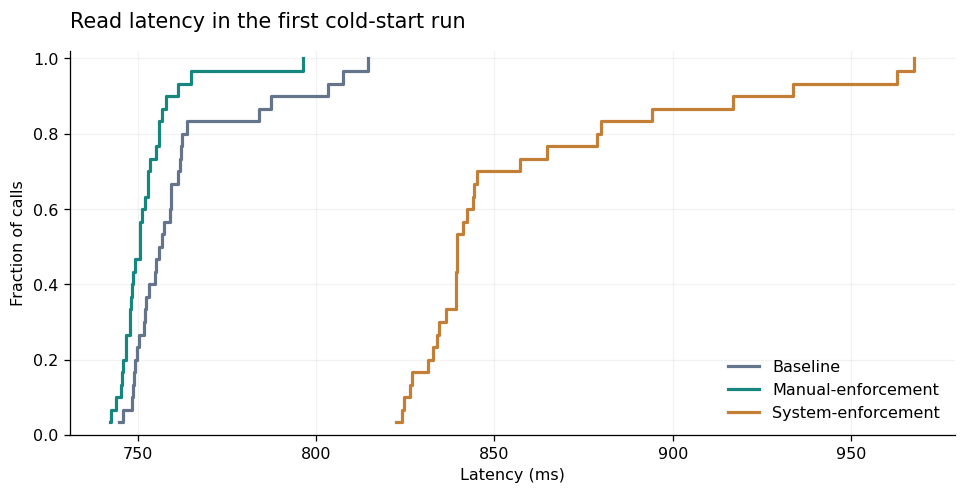

In [46]:
data = samples.query("mode == 'cold_start' and run == 1 and scenario == 'read_small'")
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for version in VERSIONS:
    values = np.sort(data.loc[data["version"] == version, "ms"])
    ax.step(values, np.arange(1, len(values) + 1) / len(values), where="post", color=COLORS[version], label=LABELS[version], linewidth=2)
ax.set(xlabel="Latency (ms)", ylabel="Fraction of calls", ylim=(0, 1.02))
ax.set_title("Read latency in the first cold-start run", loc="left", fontsize=13, pad=15)
ax.grid(alpha=.16)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "cold_start_first_run_read_latency_distribution.png", dpi=300)
plt.show()

### 2.2. Results across six runs

The six repetitions are analyzed independently before the overall comparison. Each value in the following table represents the median of 30 calls from one run.

Looking at the runs separately helps determine whether the same version remains slower throughout the experiment or whether the gap changes from one run to another.

In [47]:
data = run_stats.query("mode == 'cold_start'")
by_run = data.pivot(index=["scenario", "version"], columns="run", values="median")
by_run.index = pd.MultiIndex.from_tuples([(NAMES[s], LABELS[v]) for s, v in by_run.index], names=["Operation", "Implementation"])
display(by_run.round(2).rename_axis(columns="Run"))

Run                                   1        2        3        4        5  \
Operation   Implementation                                                    
DELETE      Baseline             775.86   777.93   838.85   776.83   795.71   
            Manual-enforcement   804.23   860.66   803.54   808.75   814.09   
            System-enforcement   859.55   873.40   944.59   860.46   838.74   
LIST        Baseline             766.81   753.92   794.49   780.25   803.69   
            Manual-enforcement   753.26   757.47   791.06   798.78   791.46   
            System-enforcement   859.41   821.62   855.60   876.61   840.13   
READ 10 MiB Baseline            1733.27  1734.06  1732.77  1762.96  1740.51   
            Manual-enforcement  1729.03  1763.13  1747.62  1750.33  1759.35   
            System-enforcement  1823.86  1834.58  1829.56  1840.15  1829.92   
READ 1 MiB  Baseline             768.12   764.99   767.46   785.42   777.27   
            Manual-enforcement   767.27   769.55   783.39   810.87   772.86   
            System-enforcement   843.68   852.04   837.89   856.25   848.40   
READ 1 KiB  Baseline             756.28   750.20   772.21   790.12   762.68   
            Manual-enforcement   750.58   755.84   784.47   789.24   754.02   
            System-enforcement   839.59   829.28   833.60   854.41   833.33   
SCHEMA      Baseline             754.68   752.62   764.60   779.51   765.64   
            Manual-enforcement   751.37   762.25   765.97   767.15   777.58   
            System-enforcement   836.82   839.90   859.93   822.53   819.49   
SEARCH      Baseline             761.52   749.08   762.42   827.48   785.05   
            Manual-enforcement   752.95   757.17   788.73   770.99   758.63   
            System-enforcement   851.41   844.04   880.93   851.23   836.92   
SELECT      Baseline             751.68   753.32   770.41   781.43   764.65   
            Manual-enforcement   760.95   768.60   761.64   769.77   782.80   
            System-enforcement   845.23   854.30   858.21   835.06   840.66   
UPDATE      Baseline             754.65   754.99   781.71   771.78   769.65   
            Manual-enforcement   754.19   784.91   773.42   766.67   792.92   
            System-enforcement   844.95   844.95   863.45   835.93   837.53   

Run                                   6  
Operation   Implementation               
DELETE      Baseline             805.76  
            Manual-enforcement   965.63  
            System-enforcement   863.49  
LIST        Baseline             781.71  
            Manual-enforcement   796.24  
            System-enforcement   834.32  
READ 10 MiB Baseline            1750.58  
            Manual-enforcement  1796.13  
            System-enforcement  1827.31  
READ 1 MiB  Baseline             828.81  
            Manual-enforcement   792.92  
            System-enforcement   847.72  
READ 1 KiB  Baseline             793.31  
            Manual-enforcement   757.85  
            System-enforcement   846.56  
SCHEMA      Baseline             791.82  
            Manual-enforcement   787.34  
            System-enforcement   838.18  
SEARCH      Baseline             764.26  
            Manual-enforcement   761.25  
            System-enforcement   836.12  
SELECT      Baseline             809.23  
            Manual-enforcement   762.67  
            System-enforcement   827.64  
UPDATE      Baseline             789.69  
            Manual-enforcement   898.53  
            System-enforcement   852.18

#### Variation between runs

READ 1 KiB provides a consistent workload for examining changes across the six runs. The lines show the median latency recorded in each run, separately for the three implementations.

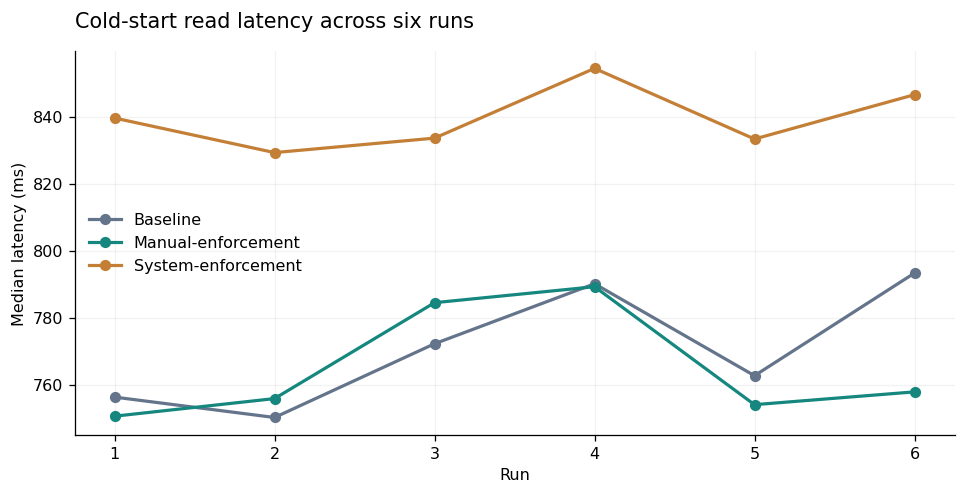

In [48]:
data = run_stats.query("mode == 'cold_start' and scenario == 'read_small'")
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for version in VERSIONS:
    rows = data[data["version"] == version].sort_values("run")
    ax.plot(rows["run"], rows["median"], marker="o", linewidth=2, color=COLORS[version], label=LABELS[version])
ax.set(xlabel="Run", ylabel="Median latency (ms)", xticks=range(1, 7))
ax.set_title("Cold-start read latency across six runs", loc="left", fontsize=13, pad=15)
ax.grid(alpha=.16)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "cold_start_read_latency_across_six_runs.png", dpi=300)
plt.show()

#### Overall latency statistics

The following table combines the results of six runs for each scenario. Mean latency is averaged across run means. The median, p90, p95, p99, SD and IQR summarize the corresponding run-level statistics. Between-run SD is calculated from the six run medians. Minimum and maximum refer to individual measured calls.

Results remain separated by operation. Averaging the nine workloads into one latency figure would give the large-file read disproportionate influence over the comparison.

In [49]:
data = summary.query("mode == 'cold_start'").copy()
data["Operation"] = data["scenario"].map(NAMES)
data["Implementation"] = data["version"].map(LABELS)
columns = {"n": "Calls", "mean": "Mean", "median": "Median", "p90": "p90", "p95": "p95", "p99": "p99", "sd": "SD", "iqr": "IQR", "run_sd": "Between-run SD", "minimum": "Min", "maximum": "Max"}
display(data.set_index(["Operation", "Implementation"])[list(columns)].rename(columns=columns).round(2))

Calls     Mean   Median      p90      p95  \
Operation   Implementation                                                  
DELETE      Baseline              180   802.02   786.82   805.73   830.72   
            Manual-enforcement    180   851.90   811.42   874.15   892.79   
            System-enforcement    180   887.22   861.98   925.19   961.26   
LIST        Baseline              180   791.30   780.98   844.33   853.64   
            Manual-enforcement    180   788.35   791.26   833.52   844.97   
            System-enforcement    180   856.75   847.87   902.67   929.48   
READ 10 MiB Baseline              180  1795.27  1737.29  1989.33  2029.76   
            Manual-enforcement    180  1794.13  1754.84  1956.77  1968.35   
            System-enforcement    180  1885.99  1829.74  2035.92  2046.70   
READ 1 MiB  Baseline              180   788.69   772.70   798.08   814.81   
            Manual-enforcement    180   785.77   778.13   789.58   800.77   
            System-enforcement    180   855.29   848.06   881.41   904.88   
READ 1 KiB  Baseline              180   776.93   767.44   801.05   823.37   
            Manual-enforcement    180   769.19   756.84   790.52   812.40   
            System-enforcement    180   847.09   836.59   880.93   888.38   
SCHEMA      Baseline              180   773.18   765.12   786.11   796.76   
            Manual-enforcement    180   774.95   766.56   801.38   810.03   
            System-enforcement    180   844.63   837.50   885.81   906.29   
SEARCH      Baseline              180   781.43   763.34   794.59   803.24   
            Manual-enforcement    180   774.36   759.94   783.27   803.60   
            System-enforcement    180   859.28   847.63   893.17   914.84   
SELECT      Baseline              180   776.38   767.53   785.23   793.17   
            Manual-enforcement    180   777.00   765.63   808.91   833.08   
            System-enforcement    180   855.59   842.95   898.30   908.98   
UPDATE      Baseline              180   774.82   770.72   804.02   815.54   
            Manual-enforcement    180   800.94   779.16   843.25   871.24   
            System-enforcement    180   856.26   844.95   889.73   901.91   

                                    p99      SD     IQR  Between-run SD  \
Operation   Implementation                                                
DELETE      Baseline             877.70   24.77   14.55           24.61   
            Manual-enforcement   936.05   43.58   58.47           63.91   
            System-enforcement   997.14   39.93   28.83           36.68   
LIST        Baseline             878.67   32.79   35.21           18.04   
            Manual-enforcement   863.86   25.26   33.88           20.40   
            System-enforcement   941.65   35.00   48.42           19.76   
READ 10 MiB Baseline            2058.49  109.81   32.21           12.16   
            Manual-enforcement  1973.24   89.74   49.53           22.30   
            System-enforcement  2102.82  104.34  210.40            5.73   
READ 1 MiB  Baseline             856.64   22.00   13.62           24.16   
            Manual-enforcement   811.20   11.70   14.77           16.77   
            System-enforcement   923.53   24.03   22.23            6.40   
READ 1 KiB  Baseline             841.07   23.62   19.40           17.79   
            Manual-enforcement   834.29   22.69   21.13           16.91   
            System-enforcement   906.41   22.29   27.80            9.48   
SCHEMA      Baseline             828.64   17.83   16.25           15.04   
            Manual-enforcement   862.02   27.33   16.19           12.47   
            System-enforcement   930.38   29.29   25.91           14.47   
SEARCH      Baseline             848.03   25.74   21.80           28.22   
            Manual-enforcement   820.85   17.84   16.78           13.12   
            System-enforcement   955.80   34.72   38.67           16.49   
SELECT      Baseline             810.38   14.39   15.61           21.42  

#### Latency across operations

The six-run summaries compare median and p90 latency for the same seven operations. The heavier file-read workloads are analyzed separately below.


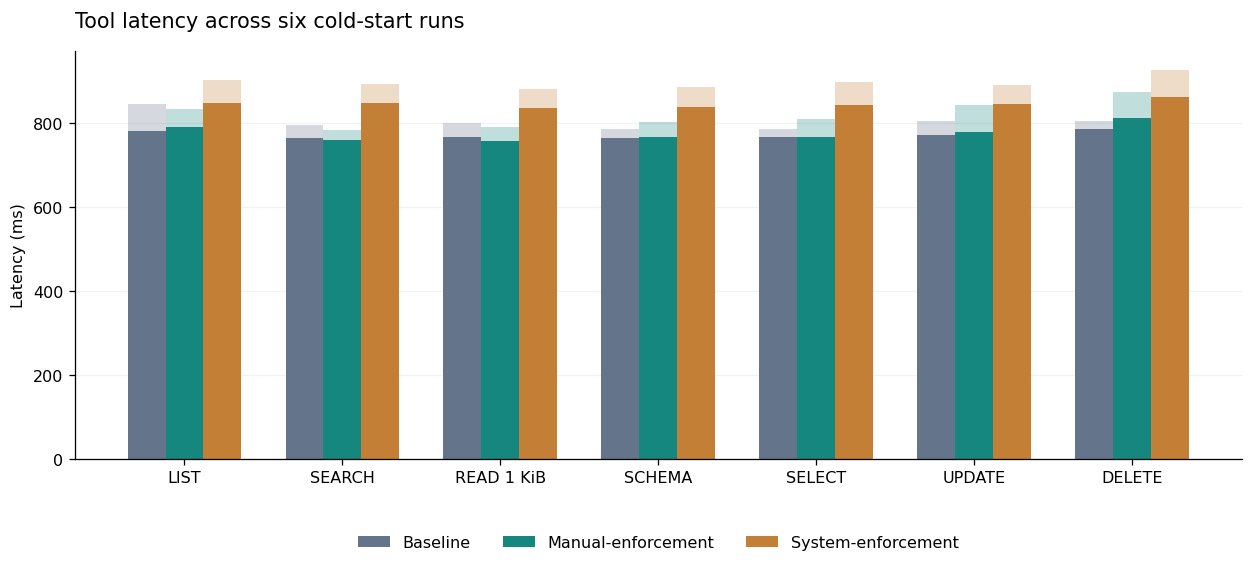

In [50]:
data = summary.query("mode == 'cold_start' ")
operations = SHORT_OPS
fig, ax = plt.subplots(figsize=(11, 5.1))
x, width = np.arange(len(operations)), .24
for i, version in enumerate(VERSIONS):
    rows = data[data["version"] == version].set_index("scenario").loc[operations]
    pos = x + (i - 1) * width
    ax.bar(pos, rows["median"], width, color=COLORS[version], label=LABELS[version])
    ax.bar(pos, rows["p90"] - rows["median"], width, bottom=rows["median"], color=COLORS[version], alpha=.27)
ax.set_xticks(x, [NAMES[s] for s in operations])
ax.set_ylabel("Latency (ms)")
ax.set_title("Tool latency across six cold-start runs", loc="left", fontsize=13, pad=15)
ax.grid(axis="y", alpha=.16)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(.5, -.15))
fig.tight_layout()
fig.savefig(FIGURES / "cold_start_tool_latency_six_run_summary.png", dpi=300, bbox_inches="tight")
plt.show()

#### File-read size and latency

The file-read workloads return files of approximately 1 KiB, 1 MiB and 10 MiB. Their input sizes are held constant across implementations, making them useful for examining how the relative impact of enforcement changes with the amount of data transferred.

Comparing these sizes helps distinguish overhead that is relatively constant per call from additional work that grows as more data is read.

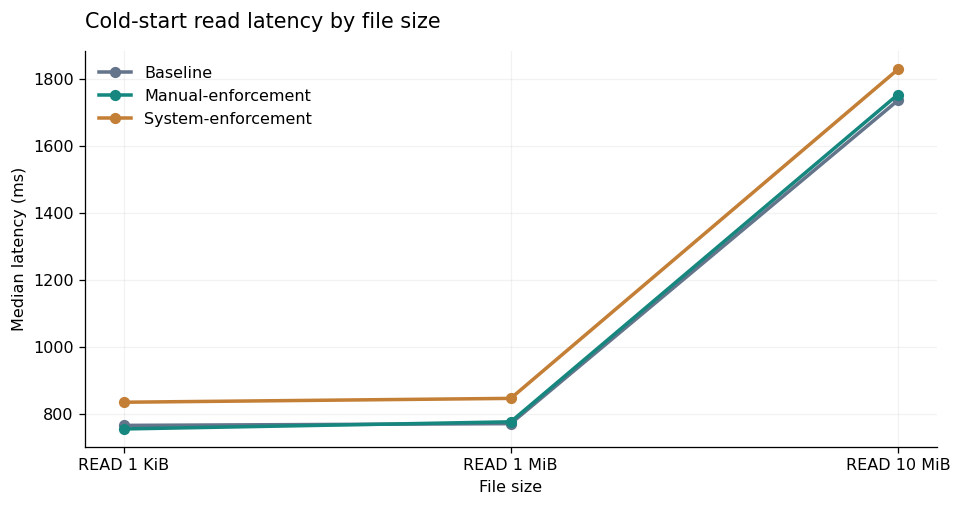

In [51]:
data = summary.query("mode == 'cold_start'")
fig, ax = plt.subplots(figsize=(8.5, 4.5))
for version in VERSIONS:
    rows = data[data["version"] == version].set_index("scenario").loc[READS]
    ax.plot(range(3), rows["median"], marker="o", linewidth=2.2, color=COLORS[version], label=LABELS[version])
ax.set_xticks(range(3), [NAMES[s] for s in READS])
ax.set(xlabel="File size", ylabel="Median latency (ms)")
ax.set_title("Cold-start read latency by file size", loc="left", fontsize=13, pad=15)
ax.grid(alpha=.16)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "cold_start_read_latency_by_file_size.png", dpi=300)
plt.show()

### 2.3. Runtime overhead

The same operation is compared between implementations within each run. The differences are then summarized across six runs. Positive values indicate that the first implementation is slower; negative values indicate that it is faster. The table reports both milliseconds and percentages, with a 95% confidence interval for the mean difference.

The three comparisons answer different questions: the cost of manual checks, the cost of the System relative to Baseline, and the difference between the two secured implementations.

In [52]:
data = overhead.query("mode == 'cold_start'").copy()
data["Operation"] = data["scenario"].map(NAMES)
columns = {"mean_ms": "Mean Δ (ms)", "median_ms": "Median Δ (ms)", "mean_pct": "Mean Δ (%)", "median_pct": "Median Δ (%)", "ci_low": "95% CI low", "ci_high": "95% CI high"}
display(data.set_index(["Operation", "comparison"])[list(columns)].rename(columns=columns).round(2))

Mean Δ (ms)  Median Δ (ms)  Mean Δ (%)  \
Operation   comparison                                                   
DELETE      Manual vs Baseline        47.66          30.14        6.06   
            System vs Baseline        78.22          83.66        9.83   
            System vs Manual          30.56          38.19        4.13   
LIST        Manual vs Baseline         1.23           0.06        0.16   
            System vs Baseline        67.80          64.40        8.73   
            System vs Manual          66.57          64.35        8.57   
READ 10 MiB Manual vs Baseline        15.24          16.84        0.88   
            System vs Baseline        88.54          90.00        5.08   
            System vs Manual          73.30          76.69        4.18   
READ 1 MiB  Manual vs Baseline         0.80           1.85        0.15   
            System vs Baseline        65.65          70.98        8.47   
            System vs Manual          64.85          65.17        8.32   
READ 1 KiB  Manual vs Baseline        -5.47          -3.29       -0.69   
            System vs Baseline        68.66          67.47        8.94   
            System vs Manual          74.13          76.37        9.72   
SCHEMA      Manual vs Baseline         0.47          -0.97        0.07   
            System vs Baseline        68.00          68.00        8.89   
            System vs Manual          67.53          66.51        8.82   
SEARCH      Manual vs Baseline       -10.02          -5.79       -1.20   
            System vs Baseline        75.14          80.87        9.82   
            System vs Manual          85.15          83.55       11.13   
SELECT      Manual vs Baseline        -4.04           0.26       -0.46   
            System vs Baseline        71.73          81.91        9.39   
            System vs Manual          75.78          74.78        9.88   
UPDATE      Manual vs Baseline        24.69          11.40        3.16   
            System vs Baseline        76.09          74.81        9.90   
            System vs Manual          51.39          64.65        6.80   

                                Median Δ (%)  95% CI low  95% CI high  
Operation   comparison                                                 
DELETE      Manual vs Baseline          3.88      -22.24       117.56  
            System vs Baseline         10.78       53.51       102.92  
            System vs Manual            4.71      -52.38       113.50  
LIST        Manual vs Baseline          0.02      -12.87        15.34  
            System vs Baseline          8.34       43.47        92.14  
            System vs Manual            8.31       41.58        91.56  
READ 10 MiB Manual vs Baseline          0.97       -7.17        37.65  
            System vs Baseline          5.18       78.20        98.87  
            System vs Manual            4.37       49.38        97.21  
READ 1 MiB  Manual vs Baseline          0.24      -21.35        22.95  
            System vs Baseline          9.16       40.73        90.58  
            System vs Manual            8.37       48.97        80.74  
READ 1 KiB  Manual vs Baseline         -0.43      -22.83        11.90  
            System vs Baseline          8.70       56.82        80.50  
            System vs Manual           10.12       58.10        90.16  
SCHEMA      Manual vs Baseline         -0.13       -9.15        10.09  
            System vs Baseline          8.96       44.02        91.98  
            System vs Manual            8.70       45.49        89.57  
SEARCH      Manual vs Baseline         -0.76      -40.16        20.13  
            System vs Baseline         10.60       39.76       110.52  
            System vs Manual           10.94       75.69        94.62  
SELECT      Manual vs Baseline          0.05      -29.46        21.37  
            System vs Baseline         10.67       39.29       104.18  
            System vs Manual            9.80       59.85        91.70  
UPDATE      M

#### Overhead by operation

The chart compares Manual-enforcement and System-enforcement with Baseline, and System-enforcement with Manual-enforcement, for each operation. Values are mean latency differences across six runs.


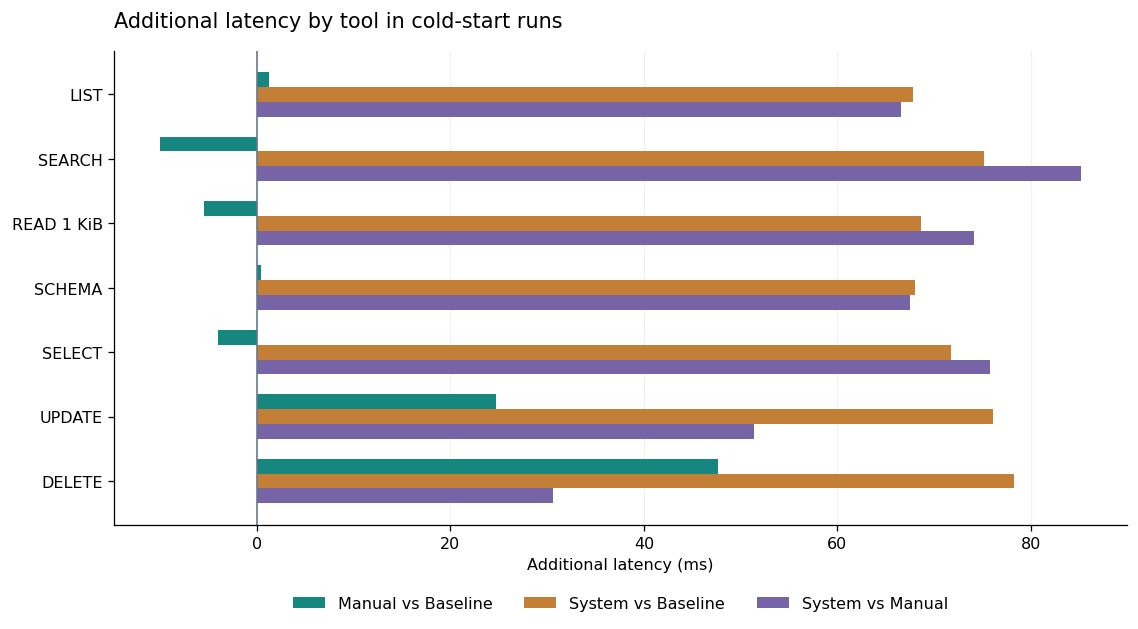

In [53]:
data = overhead.query("mode == 'cold_start' and scenario in @SHORT_OPS")
operations = SHORT_OPS
fig, ax = plt.subplots(figsize=(10, 5.6))
y, height = np.arange(len(operations)), .23
for i, (_, _, name) in enumerate(PAIRS):
    rows = data[data["comparison"] == name].set_index("scenario").loc[operations]
    ax.barh(y + (i - 1) * height, rows["mean_ms"], height, color=PAIR_COLORS[i], label=name)
ax.set_yticks(y, [NAMES[s] for s in operations])
ax.invert_yaxis()
ax.axvline(0, color="#64748b", linewidth=1)
ax.set_xlabel("Additional latency (ms)")
ax.set_title("Additional latency by tool in cold-start runs", loc="left", fontsize=13, pad=15)
ax.grid(axis="x", alpha=.16)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(.5, -.12))
fig.tight_layout()
fig.savefig(FIGURES / "cold_start_overhead_by_tool.png", dpi=300, bbox_inches="tight")
plt.show()

## 3. Persistent-session experiment

The Cold-start results include repeated process initialization. The Persistent-session experiment reuses one initialized MCP session for each scenario, allowing the execution paths of the three implementations to be compared without launching a new server for every call. This does not remove authorization checks from the secure implementations.

For short operations, the time spent starting and closing a server can be much larger than the operation itself. Reusing a session makes the differences between the actual tool execution paths easier to examine.

### 3.1. Run 1 results

The first run is examined before combining repeated runs. The table reports the complete statistics from the 30 timed calls for each operation and implementation. All latency values are in milliseconds.

In [54]:
data = run_stats.query("mode == 'persistent_session' and run == 1").copy()
data["Operation"] = data["scenario"].map(NAMES)
data["Implementation"] = data["version"].map(LABELS)
columns = {"n": "Calls", "mean": "Mean", "median": "Median", "p90": "p90", "p95": "p95", "p99": "p99", "sd": "SD", "iqr": "IQR", "minimum": "Min", "maximum": "Max"}
display(data.set_index(["Operation", "Implementation"])[list(columns)].rename(columns=columns).round(3))

,,Calls,Mean,Median,p90,p95,p99,SD,IQR,Min,Max
Operation,Implementation,,,,,,,,,,
DELETE,Baseline,30,4.621,4.187,5.610,8.057,8.452,1.255,0.386,3.923,8.549
LIST,Baseline,30,1.304,1.273,1.428,1.478,1.551,0.090,0.075,1.203,1.574
READ 10 MiB,Baseline,30,1203.108,1194.037,1240.781,1251.550,1260.025,28.455,42.805,1146.860,1261.613
READ 1 MiB,Baseline,30,14.308,14.246,14.762,14.991,15.104,0.423,0.706,13.715,15.110
READ 1 KiB,Baseline,30,1.232,1.207,1.320,1.354,1.378,0.056,0.060,1.176,1.382
SCHEMA,Baseline,30,1.317,1.261,1.469,1.542,1.621,0.110,0.113,1.230,1.630
SEARCH,Baseline,30,1.502,1.474,1.635,1.722,1.779,0.100,0.099,1.397,1.779
SELECT,Baseline,30,1.334,1.313,1.429,1.452,1.539,0.080,0.121,1.230,1.573
UPDATE,Baseline,30,1.649,1.566,1.874,1.961,2.358,0.213,0.103,1.461,2.510


#### Latency by operation

Median and p90 latency are compared for the seven filesystem and database operations. The larger file reads are examined separately below.


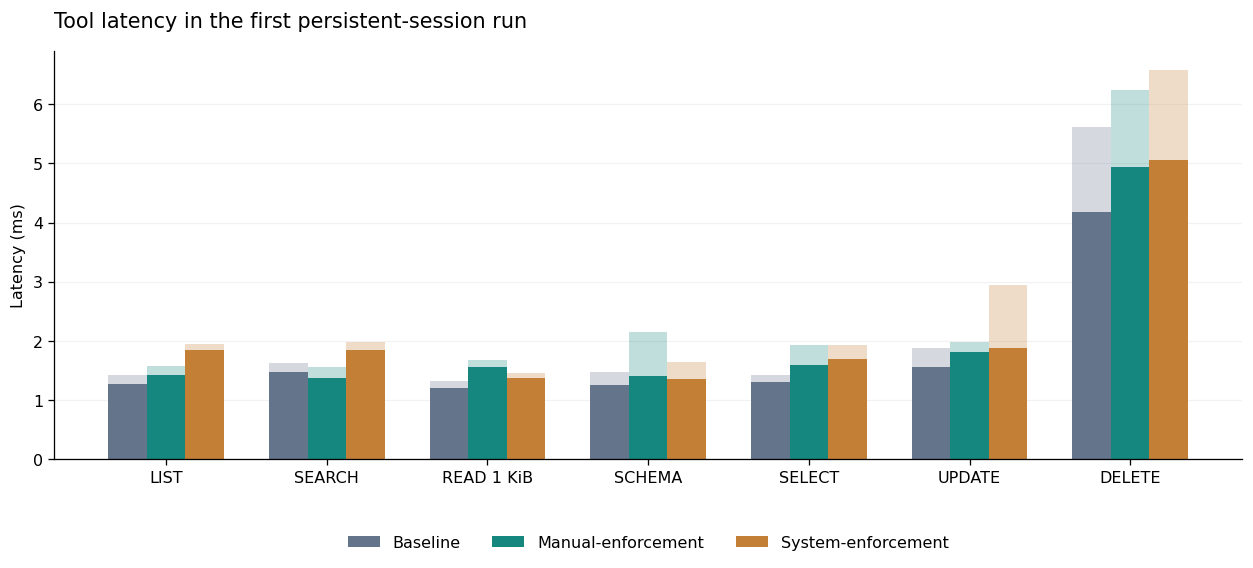

In [55]:
data = run_stats.query("mode == 'persistent_session' and run == 1")
operations = SHORT_OPS
fig, ax = plt.subplots(figsize=(11, 5.1))
x, width = np.arange(len(operations)), .24
for i, version in enumerate(VERSIONS):
    rows = data[data["version"] == version].set_index("scenario").loc[operations]
    pos = x + (i - 1) * width
    ax.bar(pos, rows["median"], width, color=COLORS[version], label=LABELS[version])
    ax.bar(pos, rows["p90"] - rows["median"], width, bottom=rows["median"], color=COLORS[version], alpha=.27)
ax.set_xticks(x, [NAMES[s] for s in operations])
ax.set_ylabel("Latency (ms)")
ax.set_title("Tool latency in the first persistent-session run", loc="left", fontsize=13, pad=15)
ax.grid(axis="y", alpha=.16)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(.5, -.15))
fig.tight_layout()
fig.savefig(FIGURES / "persistent_session_first_run_tool_latency.png", dpi=300, bbox_inches="tight")
plt.show()

#### Distribution of file-read latency

The distribution for READ 1 KiB retains the individual measurements rather than reducing them to a single summary. A curve further to the left indicates faster calls; a steeper curve indicates less variation.

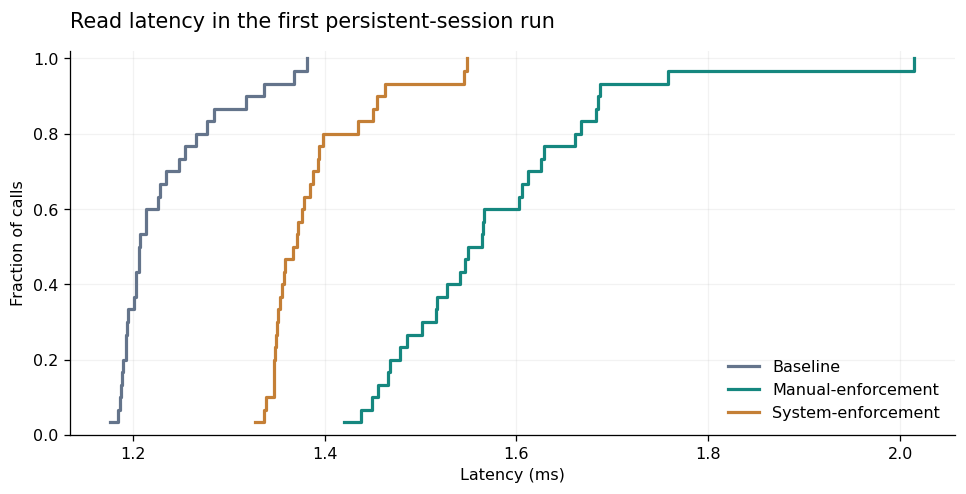

In [56]:
data = samples.query("mode == 'persistent_session' and run == 1 and scenario == 'read_small'")
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for version in VERSIONS:
    values = np.sort(data.loc[data["version"] == version, "ms"])
    ax.step(values, np.arange(1, len(values) + 1) / len(values), where="post", color=COLORS[version], label=LABELS[version], linewidth=2)
ax.set(xlabel="Latency (ms)", ylabel="Fraction of calls", ylim=(0, 1.02))
ax.set_title("Read latency in the first persistent-session run", loc="left", fontsize=13, pad=15)
ax.grid(alpha=.16)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "persistent_session_first_run_read_latency_distribution.png", dpi=300)
plt.show()

### 3.2. Results across six runs

The six repetitions are analyzed independently before the overall comparison. Each value in the following table represents the median of 30 calls from one run.

Since startup is not repeated for every call, the six-run results are particularly important for checking whether small latency differences are consistent.

In [57]:
data = run_stats.query("mode == 'persistent_session'")
by_run = data.pivot(index=["scenario", "version"], columns="run", values="median")
by_run.index = pd.MultiIndex.from_tuples([(NAMES[s], LABELS[v]) for s, v in by_run.index], names=["Operation", "Implementation"])
display(by_run.round(3).rename_axis(columns="Run"))

Run                                    1         2         3         4  \
Operation   Implementation                                               
DELETE      Baseline               4.187     4.198     4.802     4.919   
            Manual-enforcement     4.931     5.637     5.651     6.435   
            System-enforcement     5.063     5.094     6.311     5.956   
LIST        Baseline               1.273     1.289     1.629     1.439   
            Manual-enforcement     1.433     1.607     1.822     1.736   
            System-enforcement     1.856     1.917     2.564     2.214   
READ 10 MiB Baseline            1194.037  1207.909  1372.095  1352.075   
            Manual-enforcement  1185.638  1361.857  1396.752  1403.803   
            System-enforcement  1193.781  1181.791  1427.795  1374.320   
READ 1 MiB  Baseline              14.246    13.827    16.136    16.280   
            Manual-enforcement    14.423    17.337    16.375    18.737   
            System-enforcement    13.896    14.051    16.745    16.955   
READ 1 KiB  Baseline               1.207     1.181     1.364     1.347   
            Manual-enforcement     1.557     1.674     1.718     2.052   
            System-enforcement     1.369     1.341     1.791     1.575   
SCHEMA      Baseline               1.261     1.364     2.195     1.346   
            Manual-enforcement     1.404     1.415     1.607     1.504   
            System-enforcement     1.356     1.482     1.786     1.831   
SEARCH      Baseline               1.474     1.434     1.736     1.612   
            Manual-enforcement     1.378     1.504     1.500     2.092   
            System-enforcement     1.846     1.905     2.252     2.279   
SELECT      Baseline               1.313     1.374     1.501     1.341   
            Manual-enforcement     1.598     1.635     2.319     1.812   
            System-enforcement     1.689     1.573     2.032     1.954   
UPDATE      Baseline               1.566     1.467     1.939     1.840   
            Manual-enforcement     1.812     2.362     2.628     2.402   
            System-enforcement     1.874     1.848     2.501     2.451   

Run                                    5         6  
Operation   Implementation                          
DELETE      Baseline               5.938     4.743  
            Manual-enforcement     6.309     5.469  
            System-enforcement     6.728     4.996  
LIST        Baseline               1.702     1.399  
            Manual-enforcement     2.233     1.470  
            System-enforcement     2.552     2.306  
READ 10 MiB Baseline            1438.949  1295.711  
            Manual-enforcement  1498.804  1123.127  
            System-enforcement  1549.544  1439.970  
READ 1 MiB  Baseline              22.248    15.608  
            Manual-enforcement    20.297    13.983  
            System-enforcement    16.703    17.546  
READ 1 KiB  Baseline               1.602     1.361  
            Manual-enforcement     2.320     1.425  
            System-enforcement     2.320     1.905  
SCHEMA      Baseline               1.505     1.415  
            Manual-enforcement     2.116     1.266  
            System-enforcement     1.594     1.507  
SEARCH      Baseline               1.833     1.614  
            Manual-enforcement     1.815     1.306  
            System-enforcement     2.514     2.237  
SELECT      Baseline               1.480     1.401  
            Manual-enforcement     2.188     1.585  
            System-enforcement     1.866     1.879  
UPDATE      Baseline               3.633     1.647  
            Manual-enforcement     4.135     1.905  
            System-enforcement     2.756     3.355

#### Variation between runs

READ 1 KiB provides a consistent workload for examining changes across the six runs. The lines show the median latency recorded in each run, separately for the three implementations.

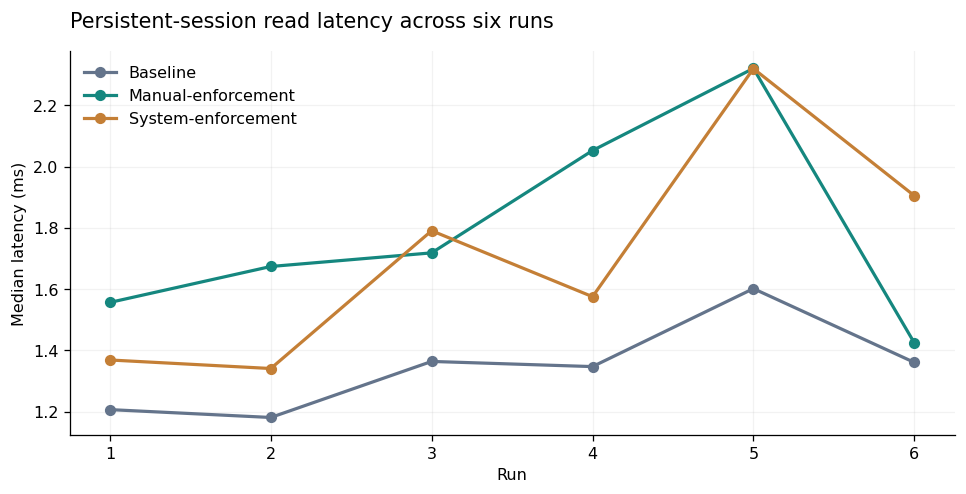

In [58]:
data = run_stats.query("mode == 'persistent_session' and scenario == 'read_small'")
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for version in VERSIONS:
    rows = data[data["version"] == version].sort_values("run")
    ax.plot(rows["run"], rows["median"], marker="o", linewidth=2, color=COLORS[version], label=LABELS[version])
ax.set(xlabel="Run", ylabel="Median latency (ms)", xticks=range(1, 7))
ax.set_title("Persistent-session read latency across six runs", loc="left", fontsize=13, pad=15)
ax.grid(alpha=.16)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "persistent_session_read_latency_across_six_runs.png", dpi=300)
plt.show()

#### Overall latency statistics

The following table combines the results of six runs for each scenario. Mean latency is averaged across run means. The median, p90, p95, p99, SD and IQR summarize the corresponding run-level statistics. Between-run SD is calculated from the six run medians. Minimum and maximum refer to individual measured calls.

The detailed table retains the slower calls and variation measures, even though the figures concentrate on median and p90. This allows the typical latency and the spread of timings to be examined together.

In [59]:
data = summary.query("mode == 'persistent_session'").copy()
data["Operation"] = data["scenario"].map(NAMES)
data["Implementation"] = data["version"].map(LABELS)
columns = {"n": "Calls", "mean": "Mean", "median": "Median", "p90": "p90", "p95": "p95", "p99": "p99", "sd": "SD", "iqr": "IQR", "run_sd": "Between-run SD", "minimum": "Min", "maximum": "Max"}
display(data.set_index(["Operation", "Implementation"])[list(columns)].rename(columns=columns).round(3))

Calls      Mean    Median       p90       p95  \
Operation   Implementation                                                      
DELETE      Baseline              180     5.889     4.772     6.899    11.668   
            Manual-enforcement    180     6.434     5.644     7.165    10.197   
            System-enforcement    180     7.051     5.525     7.118     8.794   
LIST        Baseline              180     1.487     1.419     1.585     1.634   
            Manual-enforcement    180     1.780     1.672     1.926     2.024   
            System-enforcement    180     2.285     2.260     2.521     2.613   
READ 10 MiB Baseline              180  1336.792  1323.893  1381.845  1413.207   
            Manual-enforcement    180  1360.950  1379.304  1455.896  1543.918   
            System-enforcement    180  1407.419  1401.057  1663.993  1759.197   
READ 1 MiB  Baseline              180    18.875    15.872    16.409    16.665   
            Manual-enforcement    180    17.234    16.856    18.674    18.947   
            System-enforcement    180    16.099    16.724    17.368    17.643   
READ 1 KiB  Baseline              180     1.367     1.354     1.474     1.528   
            Manual-enforcement    180     1.858     1.696     2.245     2.357   
            System-enforcement    180     1.942     1.683     2.064     2.127   
SCHEMA      Baseline              180     1.986     1.389     1.558     1.590   
            Manual-enforcement    180     1.623     1.459     1.861     1.970   
            System-enforcement    180     1.680     1.550     1.807     1.873   
SEARCH      Baseline              180     1.640     1.613     1.723     1.768   
            Manual-enforcement    180     1.659     1.502     1.809     1.864   
            System-enforcement    180     2.217     2.244     2.501     2.576   
SELECT      Baseline              180     1.419     1.388     1.546     1.630   
            Manual-enforcement    180     2.062     1.723     2.036     2.097   
            System-enforcement    180     1.940     1.872     2.214     2.310   
UPDATE      Baseline              180     2.104     1.743     2.094     2.157   
            Manual-enforcement    180     2.586     2.382     2.690     2.809   
            System-enforcement    180     2.873     2.476     2.866     3.037   

                                     p99       SD     IQR  Between-run SD  \
Operation   Implementation                                                  
DELETE      Baseline              17.748    3.571   0.644           0.640   
            Manual-enforcement    12.088    1.745   1.065           0.557   
            System-enforcement     9.960    1.335   0.529           0.744   
LIST        Baseline               1.702    0.099   0.104           0.176   
            Manual-enforcement     2.136    0.167   0.212           0.294   
            System-enforcement     2.815    0.168   0.189           0.303   
READ 10 MiB Baseline            1466.900   54.395  59.293          96.258   
            Manual-enforcement  1597.462   71.117  51.298         143.550   
            System-enforcement  1811.468  130.990  77.269         145.947   
READ 1 MiB  Baseline              17.019    0.502   0.609           3.039   
            Manual-enforcement    19.255    0.602   0.759           2.450   
            System-enforcement    18.044    0.581   0.635           1.586   
READ 1 KiB  Baseline               1.592    0.108   0.126           0.150   
            Manual-enforcement     2.529    0.291   0.382           0.334   
            System-enforcement     2.337    0.178   0.130           0.371   
SCHEMA      Baseline               1.696    0.110   0.121           0.343   
            Manual-enforcement     2.036    0.216   0.207           0.298   
            System-enforcement     1.996    0.160   0.184           0.184   
SEARCH      Baseline               1.867    0.126   0.165           0.151   
            Manual-enforcement     1.955    0.179   0.170        

#### Latency across operations

The six-run summaries compare median and p90 latency for the same seven operations with a reused MCP session.

The values are much smaller than in Cold-start, so the overhead table is important for interpreting differences that may be small in milliseconds but larger in percentage terms.

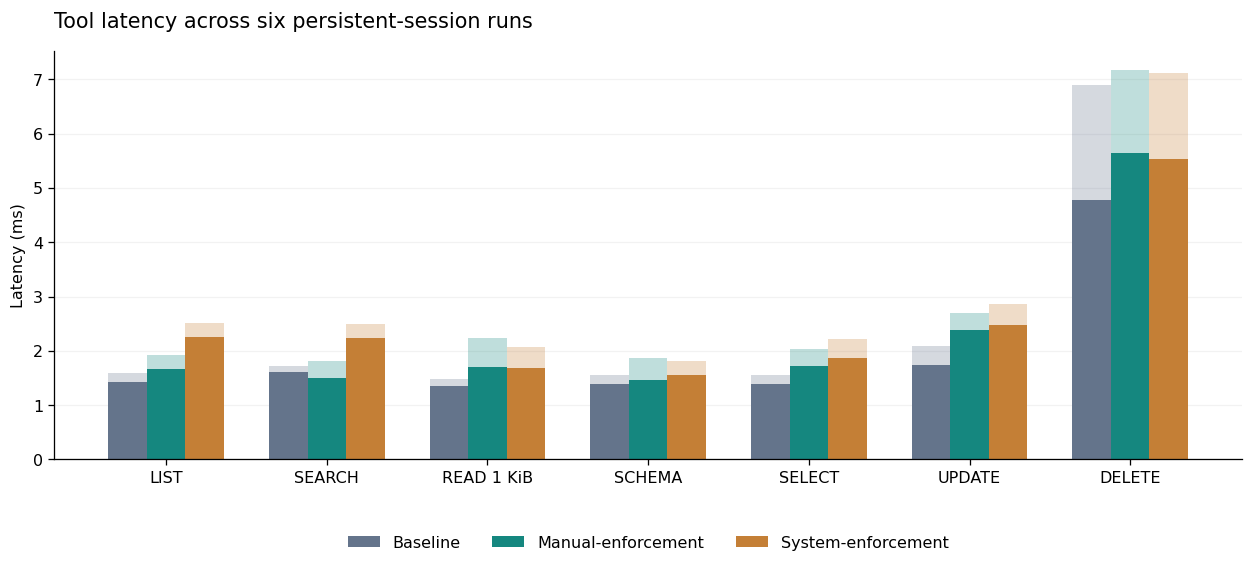

In [60]:
data = summary.query("mode == 'persistent_session' ")
operations = SHORT_OPS
fig, ax = plt.subplots(figsize=(11, 5.1))
x, width = np.arange(len(operations)), .24
for i, version in enumerate(VERSIONS):
    rows = data[data["version"] == version].set_index("scenario").loc[operations]
    pos = x + (i - 1) * width
    ax.bar(pos, rows["median"], width, color=COLORS[version], label=LABELS[version])
    ax.bar(pos, rows["p90"] - rows["median"], width, bottom=rows["median"], color=COLORS[version], alpha=.27)
ax.set_xticks(x, [NAMES[s] for s in operations])
ax.set_ylabel("Latency (ms)")
ax.set_title("Tool latency across six persistent-session runs", loc="left", fontsize=13, pad=15)
ax.grid(axis="y", alpha=.16)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(.5, -.15))
fig.tight_layout()
fig.savefig(FIGURES / "persistent_session_tool_latency_six_run_summary.png", dpi=300, bbox_inches="tight")
plt.show()

#### File-read size and latency

The file-read workloads return files of approximately 1 KiB, 1 MiB and 10 MiB. Their input sizes are held constant across implementations, making them useful for examining how the relative impact of enforcement changes with the amount of data transferred.

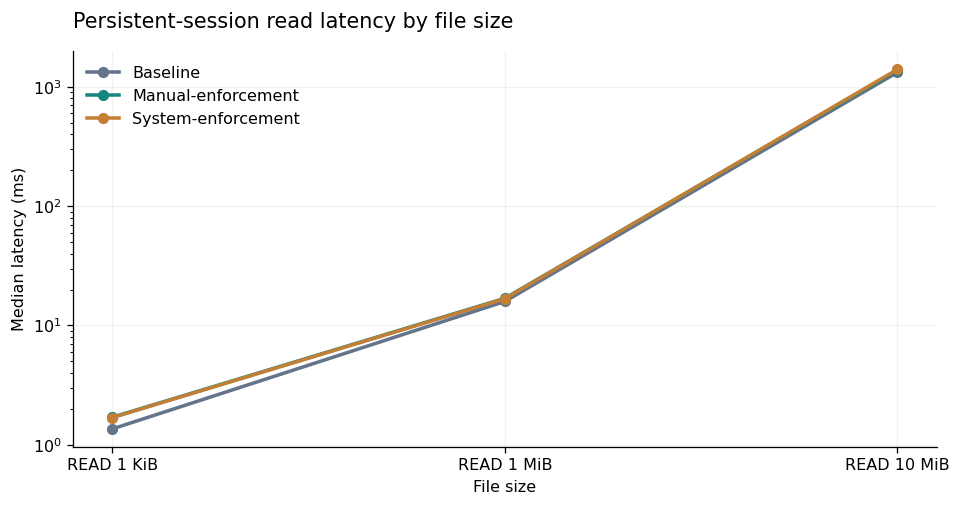

In [61]:
data = summary.query("mode == 'persistent_session'")
fig, ax = plt.subplots(figsize=(8.5, 4.5))
for version in VERSIONS:
    rows = data[data["version"] == version].set_index("scenario").loc[READS]
    ax.plot(range(3), rows["median"], marker="o", linewidth=2.2, color=COLORS[version], label=LABELS[version])
ax.set_xticks(range(3), [NAMES[s] for s in READS])
ax.set_yscale("log")
ax.set(xlabel="File size", ylabel="Median latency (ms)")
ax.set_title("Persistent-session read latency by file size", loc="left", fontsize=13, pad=15)
ax.grid(alpha=.16)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "persistent_session_read_latency_by_file_size.png", dpi=300)
plt.show()

### 3.3. Runtime overhead

The same operation is compared between implementations within each run. The differences are then summarized across six runs. Positive values indicate that the first implementation is slower; negative values indicate that it is faster. The table reports both milliseconds and percentages, with a 95% confidence interval for the mean difference.

The direct System-versus-Manual comparison is especially relevant here because both versions enforce access restrictions through different implementations.

In [62]:
data = overhead.query("mode == 'persistent_session'").copy()
data["Operation"] = data["scenario"].map(NAMES)
columns = {"mean_ms": "Mean Δ (ms)", "median_ms": "Median Δ (ms)", "mean_pct": "Mean Δ (%)", "median_pct": "Median Δ (%)", "ci_low": "95% CI low", "ci_high": "95% CI high"}
display(data.set_index(["Operation", "comparison"])[list(columns)].rename(columns=columns).round(3))

Mean Δ (ms)  Median Δ (ms)  Mean Δ (%)  \
Operation   comparison                                                   
DELETE      Manual vs Baseline        0.941          0.796      20.348   
            System vs Baseline        0.894          0.886      18.906   
            System vs Manual         -0.047         -0.170      -0.782   
LIST        Manual vs Baseline        0.262          0.245      17.674   
            System vs Baseline        0.780          0.812      53.423   
            System vs Manual          0.518          0.450      31.364   
READ 10 MiB Manual vs Baseline       18.201         38.193       1.417   
            System vs Baseline       51.071         38.972       3.723   
            System vs Manual         32.870         19.593       3.197   
READ 1 MiB  Manual vs Baseline        0.468          0.208       4.004   
            System vs Baseline       -0.408          0.417      -0.904   
            System vs Manual         -0.876         -1.155      -3.681   
READ 1 KiB  Manual vs Baseline        0.447          0.424      33.100   
            System vs Baseline        0.373          0.327      26.662   
            System vs Manual         -0.074         -0.094      -2.888   
SCHEMA      Manual vs Baseline        0.038          0.097       5.007   
            System vs Baseline        0.078          0.093       7.652   
            System vs Manual          0.041          0.123       4.755   
SEARCH      Manual vs Baseline       -0.018         -0.057      -0.921   
            System vs Baseline        0.555          0.570      34.163   
            System vs Manual          0.573          0.584      38.259   
SELECT      Manual vs Baseline        0.454          0.378      31.874   
            System vs Baseline        0.431          0.432      30.741   
            System vs Manual         -0.024          0.015       0.211   
UPDATE      Manual vs Baseline        0.526          0.532      28.723   
            System vs Baseline        0.449          0.471      31.240   
            System vs Manual         -0.077         -0.039       3.604   

                                Median Δ (%)  95% CI low  95% CI high  
Operation   comparison                                                 
DELETE      Manual vs Baseline        17.717       0.472        1.409  
            System vs Baseline        20.998       0.469        1.319  
            System vs Manual          -2.376      -0.595        0.501  
LIST        Manual vs Baseline        16.637       0.093        0.430  
            System vs Baseline        51.894       0.626        0.933  
            System vs Manual          28.514       0.286        0.750  
READ 10 MiB Manual vs Baseline         2.811     -95.249      131.651  
            System vs Baseline         2.852     -18.020      120.162  
            System vs Manual           1.455    -136.869      202.609  
READ 1 MiB  Manual vs Baseline         1.361      -1.811        2.747  
            System vs Baseline         2.698      -3.165        2.349  
            System vs Manual          -6.582      -3.668        1.916  
READ 1 KiB  Manual vs Baseline        35.354       0.187        0.708  
            System vs Baseline        24.103       0.133        0.613  
            System vs Manual          -6.049      -0.431        0.282  
SCHEMA      Manual vs Baseline         7.556      -0.377        0.452  
            System vs Baseline         7.016      -0.220        0.376  
            System vs Manual           7.959      -0.280        0.361  
SEARCH      Manual vs Baseline        -3.769      -0.312        0.276  
            System vs Baseline        34.963       0.427        0.684  
            System vs Manual          36.272       0.290        0.857  
SELECT      Manual vs Baseline        28.391       0.182        0.727  
            System vs Baseline        31.366       0.279        0.582  
            System vs Manual           0.973      -0.281        0.234  
UPDATE      M

#### Overhead by operation

The three implementation comparisons show the additional latency of authorized tool execution without repeated MCP initialization. Values are mean differences across six runs.


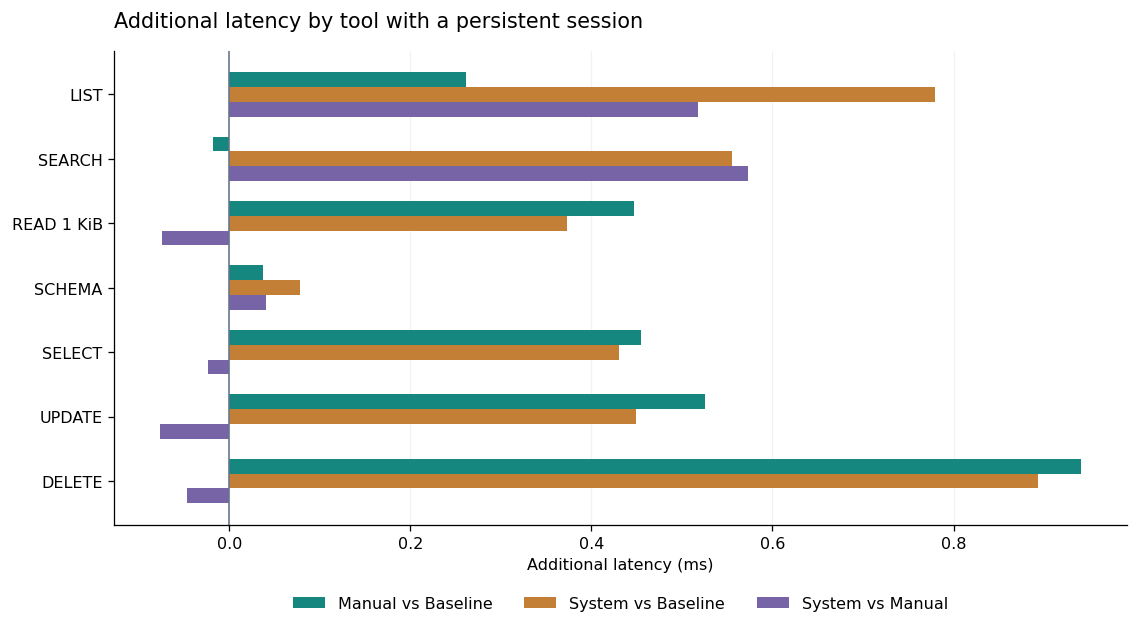

In [63]:
data = overhead.query("mode == 'persistent_session' and scenario in @SHORT_OPS")
operations = SHORT_OPS
fig, ax = plt.subplots(figsize=(10, 5.6))
y, height = np.arange(len(operations)), .23
for i, (_, _, name) in enumerate(PAIRS):
    rows = data[data["comparison"] == name].set_index("scenario").loc[operations]
    ax.barh(y + (i - 1) * height, rows["mean_ms"], height, color=PAIR_COLORS[i], label=name)
ax.set_yticks(y, [NAMES[s] for s in operations])
ax.invert_yaxis()
ax.axvline(0, color="#64748b", linewidth=1)
ax.set_xlabel("Additional latency (ms)")
ax.set_title("Additional latency by tool with a persistent session", loc="left", fontsize=13, pad=15)
ax.grid(axis="x", alpha=.16)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(.5, -.12))
fig.tight_layout()
fig.savefig(FIGURES / "persistent_session_overhead_by_tool.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Cold-start and Persistent-session comparison

The two experiments measure different execution paths. Cold-start includes repeated MCP server initialization, while Persistent-session measures tool calls after a session has been established. Their difference indicates the effect of the execution mode, not the isolated cost of an authorization decision.

The comparison therefore concerns two ways of executing the same benchmark scenarios, not two different authorization policies. We keep the performance of each tool visible instead of averaging all operations together.

### 4.1. Latency change with session reuse

The table compares median latency across the two modes for each scenario and implementation. It also reports the absolute reduction, percentage reduction and Cold-start/Persistent-session latency ratio.

In [64]:
modes = summary.pivot(index=["scenario", "version"], columns="mode", values="median").reset_index()
modes["reduction_ms"] = modes["cold_start"] - modes["persistent_session"]
modes["reduction_pct"] = 100 * modes["reduction_ms"] / modes["cold_start"]
modes["ratio"] = modes["cold_start"] / modes["persistent_session"]
modes["Operation"] = modes["scenario"].map(NAMES)
modes["Implementation"] = modes["version"].map(LABELS)
display(modes.set_index(["Operation", "Implementation"])[["cold_start", "persistent_session", "reduction_ms", "reduction_pct", "ratio"]].rename(columns={"cold_start": "Cold (ms)", "persistent_session": "Persistent (ms)", "reduction_ms": "Reduction (ms)", "reduction_pct": "Reduction (%)", "ratio": "Latency ratio"}).round(2))

mode                            Cold (ms)  Persistent (ms)  Reduction (ms)  \
Operation   Implementation                                                   
DELETE      Baseline               786.82             4.77          782.05   
            Manual-enforcement     811.42             5.64          805.77   
            System-enforcement     861.98             5.53          856.45   
LIST        Baseline               780.98             1.42          779.56   
            Manual-enforcement     791.26             1.67          789.59   
            System-enforcement     847.87             2.26          845.61   
READ 10 MiB Baseline              1737.29          1323.89          413.39   
            Manual-enforcement    1754.84          1379.30          375.53   
            System-enforcement    1829.74          1401.06          428.68   
READ 1 MiB  Baseline               772.70            15.87          756.82   
            Manual-enforcement     778.13            16.86          761.27   
            System-enforcement     848.06            16.72          831.34   
READ 1 KiB  Baseline               767.44             1.35          766.09   
            Manual-enforcement     756.84             1.70          755.15   
            System-enforcement     836.59             1.68          834.91   
SCHEMA      Baseline               765.12             1.39          763.73   
            Manual-enforcement     766.56             1.46          765.10   
            System-enforcement     837.50             1.55          835.95   
SEARCH      Baseline               763.34             1.61          761.73   
            Manual-enforcement     759.94             1.50          758.44   
            System-enforcement     847.63             2.24          845.39   
SELECT      Baseline               767.53             1.39          766.14   
            Manual-enforcement     765.63             1.72          763.91   
            System-enforcement     842.95             1.87          841.07   
UPDATE      Baseline               770.72             1.74          768.97   
            Manual-enforcement     779.16             2.38          776.78   
            System-enforcement     844.95             2.48          842.48   

mode                            Reduction (%)  Latency ratio  
Operation   Implementation                                    
DELETE      Baseline                    99.39         164.87  
            Manual-enforcement          99.30         143.76  
            System-enforcement          99.36         156.00  
LIST        Baseline                    99.82         550.35  
            Manual-enforcement          99.79         473.35  
            System-enforcement          99.73         375.16  
READ 10 MiB Baseline                    23.80           1.31  
            Manual-enforcement          21.40           1.27  
            System-enforcement          23.43           1.31  
READ 1 MiB  Baseline                    97.95          48.68  
            Manual-enforcement          97.83          46.16  
            System-enforcement          98.03          50.71  
READ 1 KiB  Baseline                    99.82         566.77  
            Manual-enforcement          99.78         446.20  
            System-enforcement          99.80         497.08  
SCHEMA      Baseline                    99.82         550.66  
            Manual-enforcement          99.81         525.27  
            System-enforcement          99.81         540.21  
SEARCH      Baseline                    99.79         473.32  
            Manual-enforcement          99.80         505.99  
            System-enforcement          99.74         377.67  
SELECT      Baseline                    99.82         553.13  
            Manual-enforcement          99.77         444.25  
            System-enforcement          99.78         450.23  
UPDATE      Baseline                    99.77         442.15  
            Manual-enforcement      

#### Reduction in execution time

The absolute reduction shows how many milliseconds are saved by reusing the MCP session. Short and long-running operations remain comparable because the chart measures the difference in milliseconds rather than percentages that approach 100% for nearly every short operation.

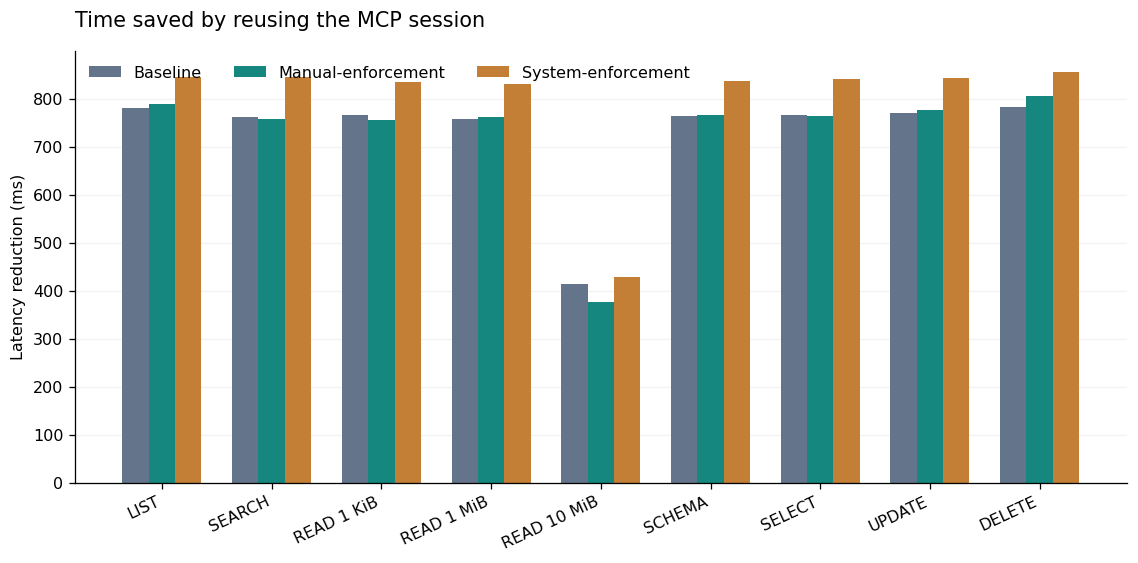

In [65]:
fig, ax = plt.subplots(figsize=(10, 5))
operations = SCENARIOS
x, width = np.arange(len(operations)), .24
for i, version in enumerate(VERSIONS):
    rows = modes[modes["version"] == version].set_index("scenario").loc[operations]
    ax.bar(x + (i - 1) * width, rows["reduction_ms"], width, color=COLORS[version], label=LABELS[version])
ax.set_xticks(x, [NAMES[s] for s in operations], rotation=25, ha="right")
ax.set_ylabel("Latency reduction (ms)")
ax.set_title("Time saved by reusing the MCP session", loc="left", fontsize=13, pad=15)
ax.grid(axis="y", alpha=.16)
ax.set_axisbelow(True)
ax.legend(ncol=3, frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "latency_reduction_with_persistent_session.png", dpi=300)
plt.show()

### 4.2. Overhead across file sizes

The file-read results compare System-enforcement with Manual-enforcement for the three payload sizes. Absolute and percentage differences are reported together, because a small difference in milliseconds can represent a large percentage for a fast operation.

Absolute overhead shows the time difference, while percentage overhead indicates how large that difference is relative to manual enforcement. Both are needed when the file sizes span several orders of magnitude.

In [66]:
data = overhead.query("scenario in @READS and comparison == 'System vs Manual'").copy()
data["Read workload"] = data["scenario"].map(NAMES)
display(data.set_index(["mode", "Read workload"])[["mean_ms", "mean_pct", "ci_low", "ci_high"]].rename(columns={"mean_ms": "Difference (ms)", "mean_pct": "Difference (%)", "ci_low": "95% CI low", "ci_high": "95% CI high"}).round(2))

Difference (ms)  Difference (%)  95% CI low  \
mode               Read workload                                                
cold_start         READ 10 MiB              73.30            4.18       49.38   
                   READ 1 MiB               64.85            8.32       48.97   
                   READ 1 KiB               74.13            9.72       58.10   
persistent_session READ 10 MiB              32.87            3.20     -136.87   
                   READ 1 MiB               -0.88           -3.68       -3.67   
                   READ 1 KiB               -0.07           -2.89       -0.43   

                                  95% CI high  
mode               Read workload               
cold_start         READ 10 MiB          97.21  
                   READ 1 MiB           80.74  
                   READ 1 KiB           90.16  
persistent_session READ 10 MiB         202.61  
                   READ 1 MiB            1.92  
                   READ 1 KiB            0.28

#### Relative overhead by file size

Percentage overhead is compared across file sizes for both execution modes. A negative value means the System was faster than Manual-enforcement for that workload.

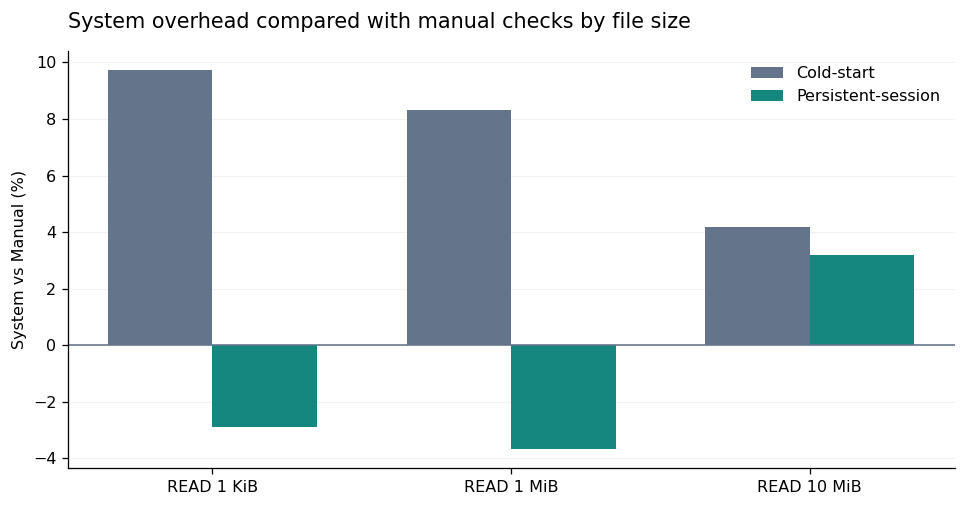

In [67]:
data = overhead.query("scenario in @READS and comparison == 'System vs Manual'")
fig, ax = plt.subplots(figsize=(8.5, 4.5))
x, width = np.arange(3), .35
for i, (mode, label, color) in enumerate([("cold_start", "Cold-start", "#64748b"), ("persistent_session", "Persistent-session", "#15877f")]):
    rows = data[data["mode"] == mode].set_index("scenario").loc[READS]
    ax.bar(x + (i - .5) * width, rows["mean_pct"], width, color=color, label=label)
ax.set_xticks(x, [NAMES[s] for s in READS])
ax.set_ylabel("System vs Manual (%)")
ax.set_title("System overhead compared with manual checks by file size", loc="left", fontsize=13, pad=15)
ax.axhline(0, color="#64748b", linewidth=1)
ax.grid(axis="y", alpha=.16)
ax.set_axisbelow(True)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "system_vs_manual_overhead_by_file_size.png", dpi=300)
plt.show()

### 4.3. Returned data and comparability

LIST, SEARCH and SCHEMA may return different amounts or scopes of information between implementations. Their observed differences can reflect both enforcement and the amount of work performed. The input and response sizes are retained to identify these cases; file reads provide a more closely matched workload.

Where an implementation returns a smaller or differently scoped result, the time difference should not be interpreted as the isolated cost of its policy checks.

In [68]:
sizes = summary[["mode", "scenario", "version", "input_bytes", "response_bytes"]].copy()
sizes["Operation"] = sizes["scenario"].map(NAMES)
sizes["Implementation"] = sizes["version"].map(LABELS)
display(sizes.set_index(["mode", "Operation", "Implementation"])[["input_bytes", "response_bytes"]].rename(columns={"input_bytes": "Input bytes", "response_bytes": "Response bytes"}).round(0))

Input bytes  Response bytes
mode               Operation   Implementation                                 
cold_start         DELETE      Baseline                    NaN            25.0
                               Manual-enforcement          NaN            17.0
                               System-enforcement          NaN            25.0
                   LIST        Baseline                    NaN           863.0
                               Manual-enforcement          NaN           188.0
                               System-enforcement          NaN           863.0
                   READ 10 MiB Baseline             10485760.0      10485760.0
                               Manual-enforcement   10485760.0      10485760.0
                               System-enforcement   10485760.0      10485760.0
                   READ 1 MiB  Baseline              1048576.0       1048576.0
                               Manual-enforcement    1048576.0       1048576.0
                               System-enforcement    1048576.0       1048576.0
                   READ 1 KiB  Baseline                 1024.0          1024.0
                               Manual-enforcement       1024.0          1024.0
                               System-enforcement       1024.0          1024.0
                   SCHEMA      Baseline                    NaN          3081.0
                               Manual-enforcement          NaN            62.0
                               System-enforcement          NaN            54.0
                   SEARCH      Baseline                    NaN           169.0
                               Manual-enforcement          NaN             9.0
                               System-enforcement          NaN            84.0
                   SELECT      Baseline                    NaN            67.0
                               Manual-enforcement          NaN            67.0
                               System-enforcement          NaN            67.0
                   UPDATE      Baseline                    NaN            30.0
                               Manual-enforcement          NaN            30.0
                               System-enforcement          NaN            30.0
persistent_session DELETE      Baseline                    NaN            25.0
                               Manual-enforcement          NaN            17.0
                               System-enforcement          NaN            25.0
                   LIST        Baseline                    NaN           863.0
                               Manual-enforcement          NaN           188.0
                               System-enforcement          NaN           863.0
                   READ 10 MiB Baseline             10485760.0      10485760.0
                               Manual-enforcement   10485760.0      10485760.0
                               System-enforcement   10485760.0      10485760.0
                   READ 1 MiB  Baseline              1048576.0       1048576.0
                               Manual-enforcement    1048576.0       1048576.0
                               System-enforcement    1048576.0       1048576.0
                   READ 1 KiB  Baseline                 1024.0          1024.0
                               Manual-enforcement       1024.0          1024.0
                               System-enforcement       1024.0          1024.0
                   SCHEMA      Baseline                    NaN          3081.0
                               Manual-enforcement          NaN            62.0
                               System-enforcement          NaN            54.0
                   SEARCH      Baseline                    NaN           169.0
                               Manual-enforcement          NaN             9.0
                               System-enforcement          NaN            84.0
                   SELECT      Baseline                    NaN            67.0
                      

## 5. Results summary

The primary architectural comparison is **System-enforcement versus Manual-enforcement** because both implementations enforce access restrictions. Baseline provides a reference for the additional runtime cost of introducing access control. Results are reported separately by operation and execution mode rather than averaged across unrelated workloads.

The table below brings together the main differences between the two secured implementations. The previous sections provide their full timing statistics, variation across runs and corresponding baseline comparisons.

The important question is whether any additional cost is concentrated in particular operations and whether those differences remain when the MCP session is reused.

In [69]:
data = overhead.query("comparison == 'System vs Manual'").copy()
data["Operation"] = data["scenario"].map(NAMES)
display(data.set_index(["mode", "Operation"])[["mean_ms", "median_ms", "mean_pct", "ci_low", "ci_high"]].rename(columns={"mean_ms": "Mean Δ (ms)", "median_ms": "Median Δ (ms)", "mean_pct": "Mean Δ (%)", "ci_low": "95% CI low", "ci_high": "95% CI high"}).round(3))

Mean Δ (ms)  Median Δ (ms)  Mean Δ (%)  \
mode               Operation                                             
cold_start         DELETE            30.557         38.185       4.126   
                   LIST              66.569         64.345       8.566   
                   READ 10 MiB       73.298         76.694       4.184   
                   READ 1 MiB        64.855         65.175       8.320   
                   READ 1 KiB        74.128         76.372       9.720   
                   SCHEMA            67.531         66.513       8.815   
                   SEARCH            85.154         83.552      11.134   
                   SELECT            75.779         74.784       9.883   
                   UPDATE            51.394         64.653       6.805   
persistent_session DELETE            -0.047         -0.170      -0.782   
                   LIST               0.518          0.450      31.364   
                   READ 10 MiB       32.870         19.593       3.197   
                   READ 1 MiB        -0.876         -1.155      -3.681   
                   READ 1 KiB        -0.074         -0.094      -2.888   
                   SCHEMA             0.041          0.123       4.755   
                   SEARCH             0.573          0.584      38.259   
                   SELECT            -0.024          0.015       0.211   
                   UPDATE            -0.077         -0.039       3.604   

                                95% CI low  95% CI high  
mode               Operation                             
cold_start         DELETE          -52.382      113.497  
                   LIST             41.578       91.559  
                   READ 10 MiB      49.384       97.212  
                   READ 1 MiB       48.965       80.744  
                   READ 1 KiB       58.097       90.159  
                   SCHEMA           45.495       89.567  
                   SEARCH           75.692       94.616  
                   SELECT           59.855       91.702  
                   UPDATE           -2.192      104.980  
persistent_session DELETE           -0.595        0.501  
                   LIST              0.286        0.750  
                   READ 10 MiB    -136.869      202.609  
                   READ 1 MiB       -3.668        1.916  
                   READ 1 KiB       -0.431        0.282  
                   SCHEMA           -0.280        0.361  
                   SEARCH            0.290        0.857  
                   SELECT           -0.281        0.234  
                   UPDATE           -1.045        0.892

### 5.1. Saved results

The full measurements, run-level statistics, six-run summaries, overhead comparisons, returned-data sizes and figures are exported for reporting and further analysis.

In [70]:
tables = {"individual_timings.csv": samples, "report_metadata.csv": report_info, "per_run_statistics.csv": run_stats, "six_run_summary.csv": summary, "per_run_differences.csv": differences, "overhead_comparison.csv": overhead, "cold_vs_persistent.csv": modes}
for filename, data in tables.items():
    data.to_csv(OUTPUT / filename, index=False)
print(f"Saved {len(tables)} result tables to {OUTPUT}")

Saved 7 result tables to /Users/enasbatarfi/agentic_security_evaluation/results/runtime_overhead/analysis
